# Light Deflection versus the Cosmological Constant

Photon trajectories in Kerr–de Sitter spacetime are integrated with RK4 from Hamilton's equations for
$H = \tfrac12 g^{\mu\nu} p_\mu p_\nu$, for positive and negative values of the cosmological constant $\Lambda$ at fixed spin.
The deflection angle is the finite-distance angle used in the main articles (Ishihara et al. 2016; Belhaj et al. 2022;
Huang et al. 2025), and the results are compared with their analytic formulas and with an exact benchmark.
The physics code lives in the `kerr_ds` package (`src/kerr_ds/`); see `docs/METHODOLOGY.md` for the full methodology.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kerr_ds import (
    analytic,
    kerr_horizon_radius,
    run_lambda_sweep,
    format_legacy_table,
    plot_trajectories,
    plot_hamiltonian_vs_step,
    plot_hamiltonian_vs_r,
    plot_deflection_shift_comparison,
    fit_curve,
    power_law,
    linear,
    plot_lambda_fit,
)

## Parameters

In [2]:
# Physical parameters
M = 1.0
a = 0.99
lambdas = [0.0, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6,
           -1e-8, -5e-8, -1e-7, -5e-7, -1e-6, -5e-6]

# Initial position of the photon (= source position r_S)
r0 = 500.0
theta0 = np.pi / 2
phi0 = 0.0

# Photon energy and impact parameter (L = b E)
E = 1.0
b = 7
L_ang = b * E

# Integration parameters
dtau = 0.05
max_steps = 30000

# Event-horizon radius for plotting and the capture condition (Kerr approximation)
rh = kerr_horizon_radius(M, a)

## Simulation

The Hamiltonian is derived symbolically **once** (once per machine, usually in about a minute, then loaded from the
cache in `~/.cache/kerr_ds/`); each value of $\Lambda$ is then integrated in parallel. The table shows the deflection
angle $\delta$ (definition of the main articles, see below) and the coordinate value $\Delta\phi - \pi$.

In [3]:
results = run_lambda_sweep(M, a, lambdas, r0, theta0, phi0, E, L_ang, rh,
                           dtau=dtau, max_steps=max_steps)

a          | Lambda     | Deflection (deg)   | dphi - pi (deg)    | Status
-------------------------------------------------------------------------------


0.99       | 0.0        | 45.508988          | 43.914885          | Steps: 20140


0.99       | 1e-08      | 45.508710          | 43.915089          | Steps: 20140


0.99       | 5e-08      | 45.507596          | 43.915907          | Steps: 20140


0.99       | 1e-07      | 45.506203          | 43.916931          | Steps: 20140


...

0.99       | -5e-08     | 45.510380          | 43.913866          | Steps: 20140


0.99       | -1e-07     | 45.511771          | 43.912850          | Steps: 20140

0.99       | -5e-07     | 45.522889          | 43.904814          | Steps: 20140


0.99       | -1e-06     | 45.536743          | 43.895073          | Steps: 20141


0.99       | -5e-06     | 45.644971          | 43.823847          | Steps: 20141


## Photon trajectories ($\Lambda \ge 0$)

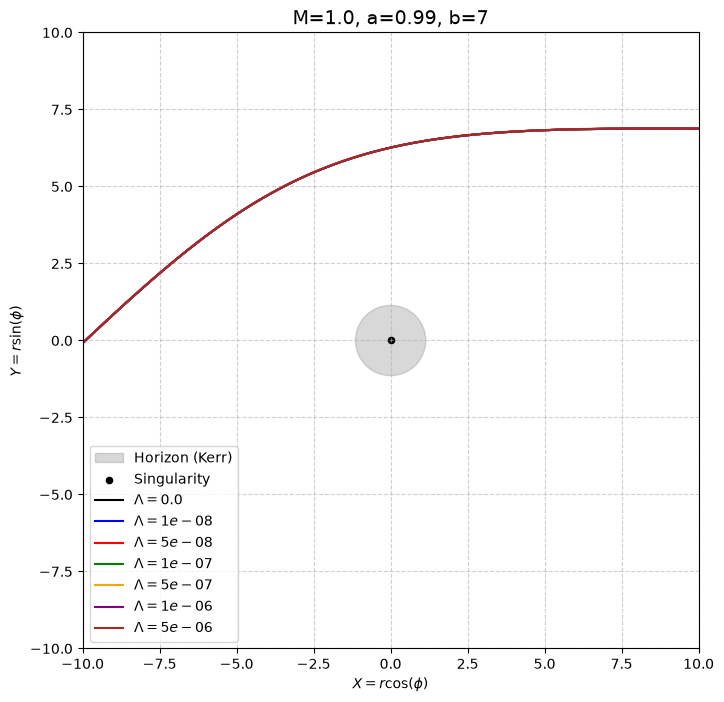

In [4]:
plot_trajectories([res for res in results if res.lmd >= 0], M, a, b, rh)
plt.show()

## Hamiltonian conservation (trajectory with the largest $\Lambda$)

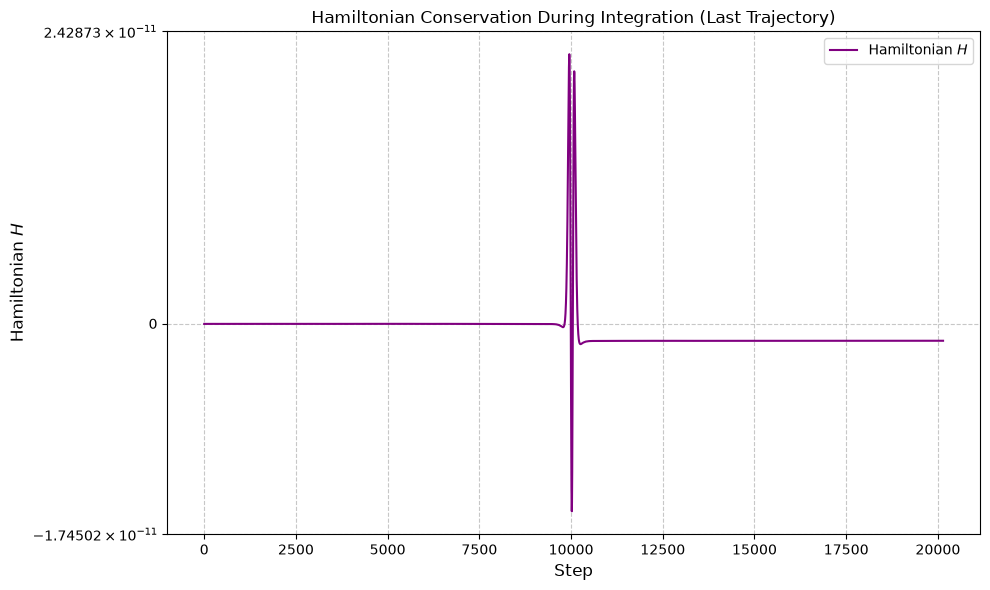

In [5]:
last = max(results, key=lambda res: res.lmd)

plot_hamiltonian_vs_step(last)
plt.show()

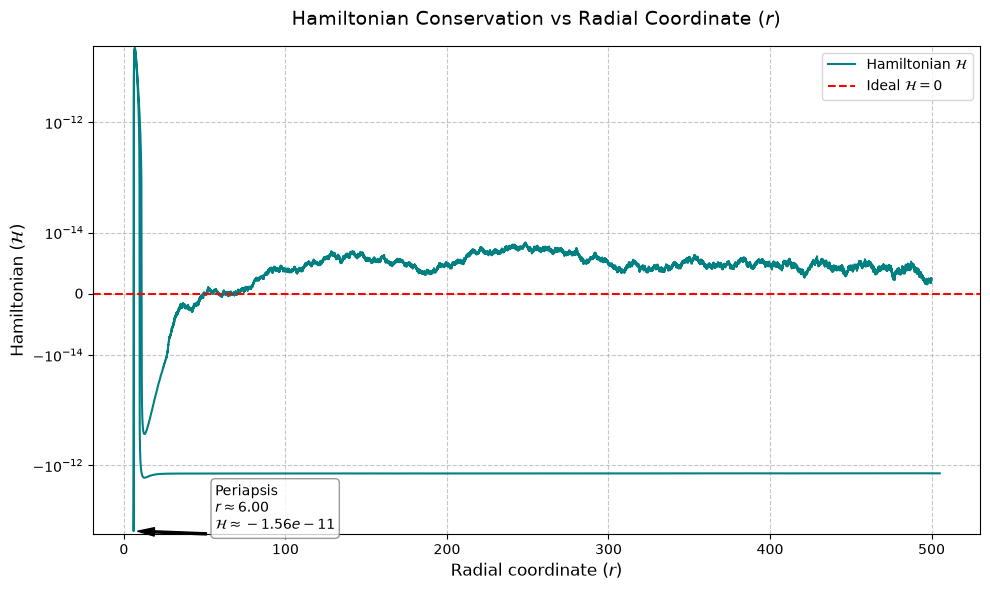

In [6]:
plot_hamiltonian_vs_r(last)
plt.show()

## Deflection angle: definition

Three quantities are stored in every `TrajectoryResult` (all in degrees):

| Attribute | Definition | Use |
|---|---|---|
| `deflection_deg` | $\delta = \Psi_O - \Psi_S + \phi_{OS}$ | **Deflection angle as defined in the main articles** (Ishihara et al. 2016; Belhaj et al. 2022, Eq. 2.1; Huang et al. 2025, Eq. 12) |
| `deflection_coord_deg` | $\phi_{OS} - \pi$ (signed) | Coordinate azimuth swept minus $\pi$ |
| `deflection_legacy_deg` | $\lvert\phi_{OS} - \pi\rvert$ | Value of the original research code (thesis tables) |

$\Psi_S$ and $\Psi_O$ are the angles between the ray and the outward radial direction measured by static observers
at the start (source, $r_S = r_0$) and at the end (observer, $r_O \approx r_0 + 5$) of the trajectory. In flat space
$\delta = 0$ exactly, whereas $\phi_{OS} - \pi = -[\arcsin(b/r_S) + \arcsin(b/r_O)]$.

The two definitions respond to $\Lambda$ with **opposite signs**: $\Lambda$ enters the measured angles $\Psi$ through
the metric (term $-\Lambda b\,(1/u_S + 1/u_O)/6$ in Huang et al., Eq. 24), while the coordinate sweep $\phi_{OS}$ alone
grows with $\Lambda$ (Huang et al., Sec. 4.1.2). Only $\delta$ is comparable with the analytic results of the articles.

In [7]:
# Table in the format of the original research code (|dphi - pi|), for comparison with the thesis tables
print(format_legacy_table(a, results))

a          | Lambda     | Deflection (deg)     | Status
-------------------------------------------------------
0.99       | 0.0        | 43.9149              | Steps: 20140
0.99       | 1e-08      | 43.9151              | Steps: 20140
0.99       | 5e-08      | 43.9159              | Steps: 20140
0.99       | 1e-07      | 43.9169              | Steps: 20140
0.99       | 5e-07      | 43.9252              | Steps: 20140
0.99       | 1e-06      | 43.9359              | Steps: 20140
0.99       | 5e-06      | 44.0355              | Steps: 20140
0.99       | -1e-08     | 43.9147              | Steps: 20140
0.99       | -5e-08     | 43.9139              | Steps: 20140
0.99       | -1e-07     | 43.9128              | Steps: 20140
0.99       | -5e-07     | 43.9048              | Steps: 20140
0.99       | -1e-06     | 43.8951              | Steps: 20141
0.99       | -5e-06     | 43.8238              | Steps: 20141



## Comparison with the main articles

The simulated deflection angle is compared with

- the **exact** finite-distance deflection angle (same definition, from the first integrals of the null geodesic by
  quadrature, `analytic.deflection_exact_deg`),
- **Huang et al. (2025), Eq. (24)** and **Belhaj et al. (2022), Eq. (5.1)**, evaluated at the same source and observer
  radii ($u_S = 1/r_0$, $u_O = 1/r_\text{end}$).

The article formulas are weak-field expansions in $M/b$; at $b = 7$ their absolute values are far from the exact
value, so the comparison uses the change with $\Lambda$, $\delta(\Lambda) - \delta(0)$. Their $\Lambda$ terms are
first order in $\Lambda r^2$: the agreement is best for $\Lambda r_0^2/3 \ll 1$ (0.083 for $\Lambda = 10^{-6}$, but
0.42 for $\Lambda = 5\times10^{-6}$, where $r_0 \approx 0.65\,r_c$).

Lambda = 0: simulation 45.508988, exact 45.508988, Huang Eq. 24 41.883, Belhaj Eq. 5.1 28.110 deg (weak-field expansions)

   Lambda |   delta sim | delta exact |  shift sim | shift exact | Huang (24) | Belhaj (5.1) | L r0^2/3
---------------------------------------------------------------------------------------------------------
   -5e-06 |   45.644971 |   45.644971 |   +0.13598 |    +0.13598 |   +0.10994 |     +0.14525 |   -0.417
   -1e-06 |   45.536743 |   45.536743 |   +0.02775 |    +0.02775 |   +0.02764 |     +0.02905 |   -0.083
   -5e-07 |   45.522889 |   45.522889 |   +0.01390 |    +0.01390 |   +0.01417 |     +0.01452 |   -0.042
   -1e-07 |   45.511771 |   45.511771 |   +0.00278 |    +0.00278 |   +0.00289 |     +0.00290 |   -0.008
   -5e-08 |   45.510380 |   45.510380 |   +0.00139 |    +0.00139 |   +0.00145 |     +0.00145 |   -0.004
   -1e-08 |   45.509266 |   45.509266 |   +0.00028 |    +0.00028 |   +0.00029 |     +0.00029 |   -0.001
    0e+00 |   45.508988 |   45.508988 |   +

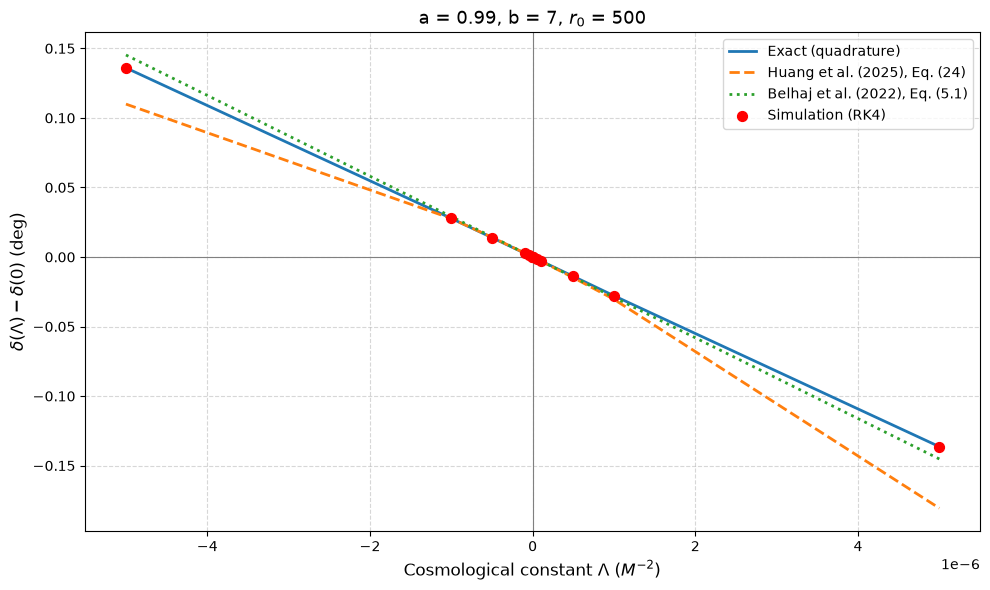

In [8]:
lmd_arr = np.array([res.lmd for res in results])
r_obs = np.array([res.r[-1] for res in results])  # observer radius = end point of each trajectory
i0 = int(np.flatnonzero(lmd_arr == 0)[0])

sim = np.array([res.deflection_deg for res in results])
exact = np.array([analytic.deflection_exact_deg(M, a, l, b, r0, ro) for l, ro in zip(lmd_arr, r_obs)])
huang = np.array([analytic.huang2025_deflection_deg(M, a, l, b, r0, ro) for l, ro in zip(lmd_arr, r_obs)])
belhaj = np.array([analytic.belhaj2022_deflection_deg(M, a, l, b, r0, ro) for l, ro in zip(lmd_arr, r_obs)])

def shift(v):
    return v - v[i0]

print(f"Lambda = 0: simulation {sim[i0]:.6f}, exact {exact[i0]:.6f}, "
      f"Huang Eq. 24 {huang[i0]:.3f}, Belhaj Eq. 5.1 {belhaj[i0]:.3f} deg (weak-field expansions)\n")
print(f"{'Lambda':>9} | {'delta sim':>11} | {'delta exact':>11} | {'shift sim':>10} | {'shift exact':>11} | "
      f"{'Huang (24)':>10} | {'Belhaj (5.1)':>12} | {'L r0^2/3':>8}")
print("-" * 105)
for k in np.argsort(lmd_arr):
    print(f"{lmd_arr[k]:>9.0e} | {sim[k]:>11.6f} | {exact[k]:>11.6f} | {shift(sim)[k]:>+10.5f} | "
          f"{shift(exact)[k]:>+11.5f} | {shift(huang)[k]:>+10.5f} | {shift(belhaj)[k]:>+12.5f} | "
          f"{lmd_arr[k] * r0**2 / 3:>8.3f}")
print(f"\nmax |simulation - exact| = {np.max(np.abs(sim - exact)):.2e} deg")

plot_deflection_shift_comparison(
    lmd_arr, shift(sim),
    {"Exact (quadrature)": shift(exact),
     "Huang et al. (2025), Eq. (24)": shift(huang),
     "Belhaj et al. (2022), Eq. (5.1)": shift(belhaj)},
    title=f"a = {a}, b = {b}, $r_0$ = {r0:g}")
plt.show()

## Deflection versus $\Lambda$: fits

For each sign of $\Lambda$ the deflection angle is fitted against $\lvert\Lambda\rvert$ with the power law
$\delta = A\,\lvert\Lambda\rvert^{B} + C$ (`scipy.optimize.curve_fit`; $\Lambda = 0$ is represented by $10^{-10}$ so
that it can be shown on a logarithmic axis), and with the linear model $\delta = A\,\lvert\Lambda\rvert + C$ for
$\lvert\Lambda\rvert \le 10^{-6}$. The 1-sigma uncertainties come from the covariance matrix of the fit.
A departure of $B$ from 1 reflects how close the source and observer are to the cosmological horizon
($\Lambda r_0^2/3$ up to 0.42), so it depends on $r_0$; $R^2 \approx 1$ for seven monotonic points is not by itself
evidence for a physical law.

Lambda > 0: delta = -23250.5469 * |Lambda|^(0.9869 ± 0.0015) + 45.5090   (R² = 0.999999)
    linear (|Lambda| <= 1e-6): delta = (-27892.96 ± 4.90) * |Lambda| + 45.508991   (R² = 1.000000)
Lambda < 0: delta = 23442.1158 * |Lambda|^(0.9878 ± 0.0010) + 45.5090   (R² = 0.999999)
    linear (|Lambda| <= 1e-6): delta = (27758.17 ± 11.15) * |Lambda| + 45.508993   (R² = 0.999999)


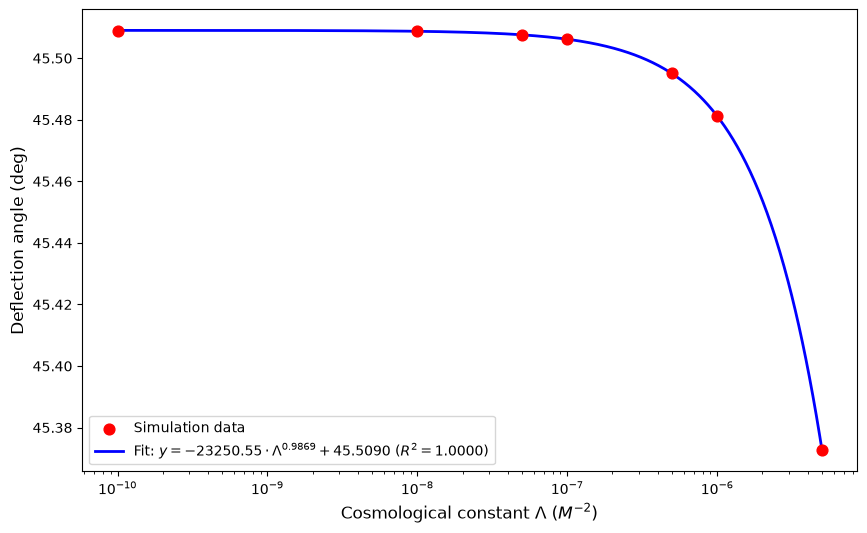

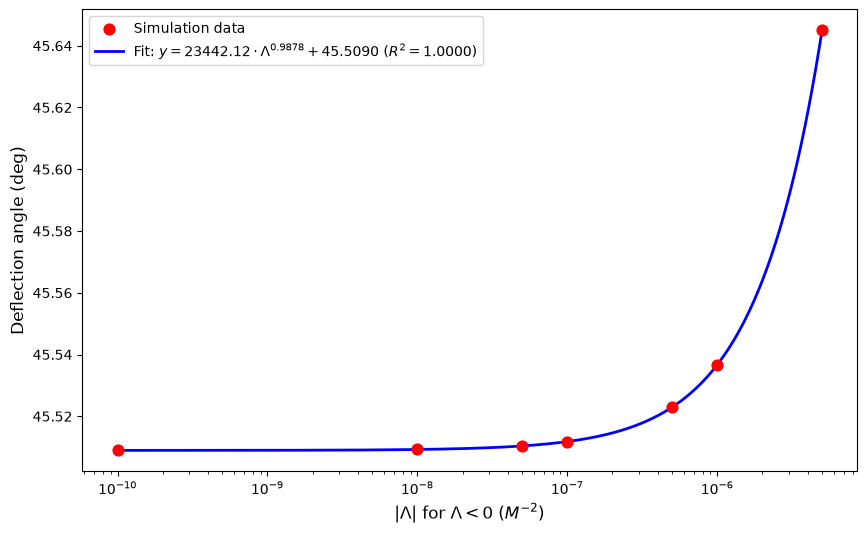

In [9]:
fits = {}
for sign, name in ((+1, "Lambda > 0"), (-1, "Lambda < 0")):
    sel = (np.sign(lmd_arr) == sign) | (lmd_arr == 0)
    order = np.argsort(np.abs(lmd_arr[sel]))
    x = np.abs(lmd_arr[sel])[order]
    y = sim[sel][order]
    x_fit = np.where(x == 0, 1e-10, x)  # Lambda = 0 -> 1e-10 for the log axis

    p0 = [np.sign(y[-1] - y[0]) * 5000, 1.0, y[0]]
    popt, r2, perr = fit_curve(power_law, x_fit, y, p0=p0, maxfev=20000, return_errors=True)
    print(f"{name}: delta = {popt[0]:.4f} * |Lambda|^({popt[1]:.4f} ± {perr[1]:.4f}) + {popt[2]:.4f}"
          f"   (R² = {r2:.6f})")

    small = x <= 1e-6
    p0_lin = [(y[small][-1] - y[0]) / x[small][-1], y[0]]
    popt_lin, r2_lin, perr_lin = fit_curve(linear, x[small], y[small], p0=p0_lin, return_errors=True)
    print(f"    linear (|Lambda| <= 1e-6): delta = ({popt_lin[0]:.2f} ± {perr_lin[0]:.2f}) * |Lambda| "
          f"+ {popt_lin[1]:.6f}   (R² = {r2_lin:.6f})")
    fits[sign] = (x_fit, y, popt, r2)

plot_lambda_fit(*fits[+1])
plt.show()
plot_lambda_fit(*fits[-1], xlabel=r'$|\Lambda|$ for $\Lambda < 0$ ($M^{-2}$)')
plt.show()